# CreditParity – Step 7
**Profitable, Fair Lending Decisions**

**Step 7:** Explainability with SHAP – globally and for each application

## Step 7 · Explainability with SHAP

**Why explanations?** In CreditParity, explanations are part of the decision process, not an extra:
- 🟡 In the **yellow zone**, the credit analyst sees which factors drive the default probability.
- 🔴 In the **red zone**, the customer receives the main reasons for the automatic decline and can request a human review (GDPR Art. 22).
- The bank and supervisors can check **what the model has learned overall**.

**SHAP for a logistic regression.** SHAP splits a prediction into the contributions of the individual features. For a linear model with independent features, the SHAP value of a feature *j* is exact and simple:

$$\phi_j = \beta_j \cdot (x_j - \overline{x}_j)$$

i.e. the coefficient times the deviation of the applicant from the average applicant. The contributions are in **log-odds** and add up exactly: *average log-odds + sum of all contributions = the applicant's log-odds*, which the logistic function turns into the default probability. Positive contributions raise the risk, negative ones lower it.

**From model columns to features.** One-hot encoding turns e.g. `CheckingStatus` into several columns. Because SHAP values add up, we sum the columns of each original feature, so every explanation refers to the 20 features the applicant actually filled in.

**Models.** The final **CreditParity model** (logistic regression with partial reweighing, strength 0.5; `Age` is an input as a partial fairness correction, `Sex` and `ForeignWorker` are not; Steps 5 and 6) and, for comparison, model **(a)** (all features, no reweighing). Zone boundaries of the CreditParity model: 0.13 / 0.62 (Step 5).

**Audience.** In the CreditParity MVP, explanations are shown to the **credit analyst only**. The analyst sees all drivers. Age is shown honestly as its own line, labelled **"Age (fairness correction)"**, because in the CreditParity model its role is to offset part of the age information carried by other features. A customer-facing explanation is out of scope (see limitations).

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap          # pip install shap (pre-installed in Google Colab)

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}
UP_COLOR, DOWN_COLOR = "#C44E52", "#55A868"      # raises risk / lowers risk

T_LOWER, T_UPPER = 0.13, 0.62                     # zone boundaries of the CreditParity model, Step 5
REWEIGHING_STRENGTH = 0.5                         # partial reweighing (Step 6)
SENSITIVE = ["Age", "Sex", "ForeignWorker"]

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3 to 6
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

In [3]:
ALL_FEATURES = X.columns.tolist()
FAIR_FEATURES = [c for c in ALL_FEATURES if c not in ["Sex", "ForeignWorker"]]   # CreditParity model

def make_model(features):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in categorical if c in features]),
            ("num", StandardScaler(), [c for c in numeric if c in features])])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

def age_group(data):
    return pd.cut(data["Age"], [18, 25, 35, 50, 100],
                  labels=["19-25", "26-35", "36-50", "51+"]).astype(str)

def reweighing_weights(data, y_true, strength=1.0):
    """Kamiran & Calders reweighing on age group x sex x foreign worker status (as in Steps 5 and 6);
    with strength s the weight is (1 - s) + s * full weight."""
    group = age_group(data) + "|" + data["Sex"] + "|" + data["ForeignWorker"]
    w = pd.Series(1.0, index=data.index)
    for g in group.unique():
        for label in [0, 1]:
            m = (group == g) & (y_true == label)
            if m.any():
                w[m] = (group == g).mean() * (y_true == label).mean() / m.mean()
    return ((1 - strength) + strength * w).to_numpy()

model_cp = make_model(FAIR_FEATURES).fit(
    X_train, y_train, model__sample_weight=reweighing_weights(X_train, y_train, REWEIGHING_STRENGTH))
model_a = make_model(ALL_FEATURES).fit(X_train, y_train)
FINAL, COMPARISON = "CreditParity model – final", "(a) All features – comparison"
MODELS = {FINAL: model_cp, COMPARISON: model_a}

def display_name(feature):
    """Display name for the analyst: age is marked as the fairness correction in the CreditParity model."""
    return "Age (fairness correction)" if feature == "Age" else feature

In [4]:
def dense(m):
    return m.toarray() if hasattr(m, "toarray") else m

def original_feature(column):
    """Map a model column such as 'cat__CheckingStatus_less_0' to 'CheckingStatus'."""
    name = column.split("__", 1)[1]
    return next(f for f in X.columns if name == f or name.startswith(f + "_"))

class Explainer:
    """SHAP explanations of a fitted pipeline, aggregated to the 20 original features."""
    def __init__(self, pipeline, background):
        self.prep = pipeline.named_steps["prep"]
        self.clf = pipeline.named_steps["model"]
        Z = dense(self.prep.transform(background))
        # all training applications as background -> exact linear SHAP values
        masker = shap.maskers.Independent(Z, max_samples=len(Z))
        self.explainer = shap.LinearExplainer(self.clf, masker)
        self.columns = self.prep.get_feature_names_out()
        self.groups = [original_feature(c) for c in self.columns]

    def __call__(self, data):
        sv = self.explainer(dense(self.prep.transform(data)))
        values = pd.DataFrame(sv.values, columns=self.columns, index=data.index)
        values = values.T.groupby(self.groups).sum().T
        values = values[[c for c in X.columns if c in values.columns]]   # one column per model input
        return values, float(np.atleast_1d(sv.base_values)[0])

explainers = {name: Explainer(m, X_train) for name, m in MODELS.items()}

# Check: base value + sum of contributions = the model's log-odds
shap_cp, base_cp = explainers[FINAL](X_test)
log_odds = model_cp.decision_function(X_test)
print("Average log-odds (base value):", round(base_cp, 3))
print("Max. difference between base + sum(SHAP) and model log-odds:",
      float(np.abs(base_cp + shap_cp.sum(axis=1) - log_odds).max()))

Average log-odds (base value): -1.005
Max. difference between base + sum(SHAP) and model log-odds: 2.6645352591003757e-15


### a) Global explanation: what drives the model overall?

The mean absolute SHAP value of a feature shows how strongly it moves the predictions on average (test set, 1,000 applications).

In [5]:
shap_test = {name: explainers[name](X_test)[0] for name in MODELS}
importance = pd.DataFrame({name: s.abs().mean() for name, s in shap_test.items()})
importance = importance.sort_values(FINAL, ascending=False)
importance["Share of total (CreditParity)"] = importance[FINAL] / importance[FINAL].sum()
importance.round(3)

,CreditParity model – final,(a) All features – comparison,Share of total (CreditParity)
CheckingStatus,0.555,0.492,0.114
EmploymentDuration,0.509,0.543,0.105
OwnsProperty,0.483,0.481,0.099
InstallmentPercent,0.452,0.449,0.093
Age,0.423,0.024,0.087
LoanDuration,0.354,0.363,0.073
ExistingCreditsCount,0.318,0.312,0.065
ExistingSavings,0.313,0.259,0.064
CurrentResidenceDuration,0.292,0.301,0.060
OthersOnLoan,0.249,0.249,0.051


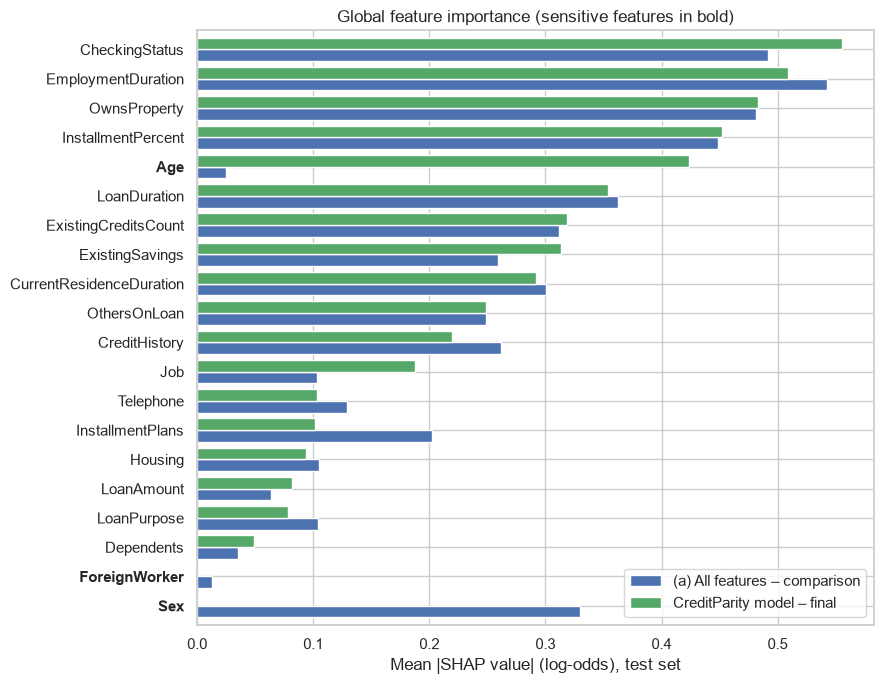

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
plot_df = importance.iloc[::-1][[COMPARISON, FINAL]].fillna(0)
plot_df.plot.barh(ax=ax, color=["#4C72B0", "#55A868"], width=0.8)
for label in ax.get_yticklabels():
    if label.get_text() in SENSITIVE:
        label.set_fontweight("bold")
ax.set_xlabel("Mean |SHAP value| (log-odds), test set")
ax.set_title("Global feature importance (sensitive features in bold)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [7]:
# Direction of the sensitive features: coefficients of both models
coef = pd.DataFrame({name: pd.Series(m.named_steps["model"].coef_[0],
                                     index=m.named_steps["prep"].get_feature_names_out())
                     for name, m in MODELS.items()})
coef.index = [c.split("__", 1)[1] for c in coef.index]
coef.loc[[c for c in coef.index if c.startswith(tuple(SENSITIVE))]].round(3)

,CreditParity model – final,(a) All features – comparison
ForeignWorker_no,NaN,0.002
ForeignWorker_yes,NaN,-0.277
Sex_female,NaN,0.213
Sex_male,NaN,-0.488
Age,-0.518,0.030


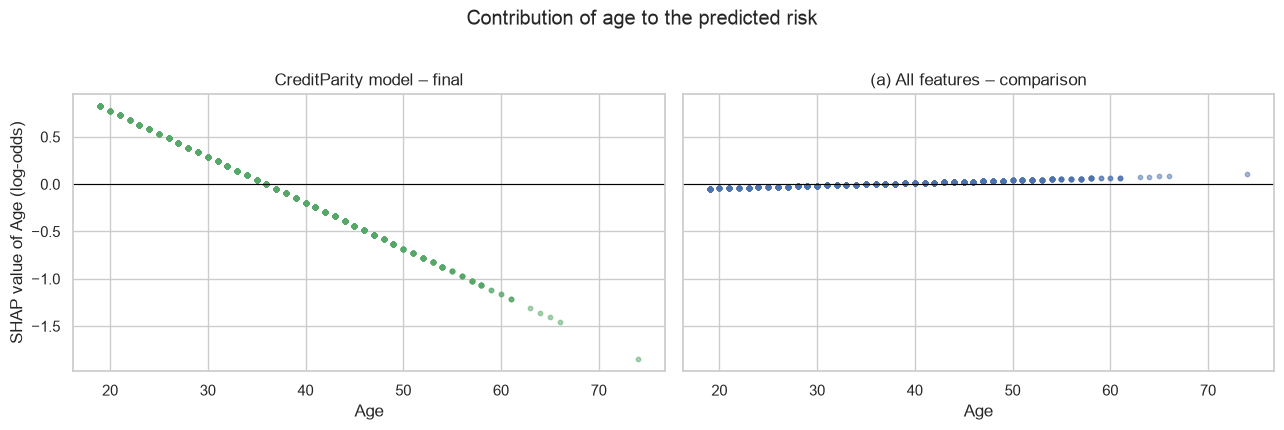

In [8]:
# How does age contribute in each model? SHAP value of Age vs. age
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (name, s) in zip(axes, shap_test.items()):
    ax.scatter(X_test["Age"], s["Age"], s=10, alpha=0.5,
               color="#55A868" if name == FINAL else "#4C72B0")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("Age")
axes[0].set_ylabel("SHAP value of Age (log-odds)")
plt.suptitle("Contribution of age to the predicted risk", y=1.02)
plt.tight_layout()
plt.show()

In [9]:
# Strongest drivers by category: average SHAP value per category level (CreditParity model, test set)
rows = []
for feat in ["CheckingStatus", "CreditHistory", "EmploymentDuration", "OwnsProperty", "ExistingSavings"]:
    for level, v in shap_test[FINAL][feat].groupby(X_test[feat]).mean().items():
        rows.append({"Feature": feat, "Value": level, "Mean SHAP": v})
pd.DataFrame(rows).set_index(["Feature", "Value"]).round(3)

Mean SHAP
Feature            Value                            
CheckingStatus     0_to_200                   -0.257
                   greater_200                 0.213
                   less_0                     -0.747
                   no_checking                 0.648
CreditHistory      all_credits_paid_back      -0.435
                   credits_paid_to_date        0.062
                   no_credits                 -1.883
                   outstanding_credit          0.390
                   prior_payments_delayed      0.057
EmploymentDuration 1_to_4                     -0.072
                   4_to_7                      0.211
                   greater_7                   1.040
                   less_1                     -0.966
                   unemployed                 -0.917
OwnsProperty       car_other                   0.318
                   real_estate                -1.116
                   savings_insurance           0.019
                   unknown                     0.975
ExistingSavings    100_to_500                 -0.009
                   500_to_1000                -0.222
                   greater_1000               -0.331
                   less_100                    0.418
                   unknown                    -0.873

**Result (a) – global explanation.**
- **Age is the fifth-strongest driver of the CreditParity model** (8.7% of all SHAP contributions), and it works in the *opposite* direction from what the raw data suggests: its coefficient is **−0.52** per standard deviation, so the older the applicant, the lower the predicted risk. In model (a), age has almost no weight (coefficient +0.03). The SHAP plot shows a straight line: age raises the risk of every applicant up to about 35 and lowers it for everyone older.
- **Why? Age works as a fairness correction.** Partial reweighing weakens the link between age group and default in the training data. The model then uses `Age` as a **counterweight to part of the age proxies** found in Step 6. For example, `EmploymentDuration = greater_7` still raises the risk (+1.04 on average), and the age term offsets part of this effect that comes from the applicant's age. This is why the dashboard labels it **"Age (fairness correction)"**.
- **Gender and foreign worker status are not inputs of the CreditParity model**, so they never appear in its explanations. Two applicants who differ only in gender get the same score and the same explanation.
- **The other main drivers** are the same in both models: checking account status, employment duration, property, installment rate and loan duration.
- **Implausible patterns become visible.** Because the dataset is synthetic, some explanations contradict banking intuition: a negative checking balance (`less_0`, −0.75) and having no previous credits (`no_credits`, −1.88) *lower* the risk, while having no checking account (+0.65) and long employment (`greater_7`, +1.04) *raise* it; unemployed applicants get a lower risk (−0.92). SHAP describes the model faithfully; it cannot tell whether what the model learned makes sense. Analysts need to be aware of this.

### b) Local explanation: why this decision for this applicant?

For individual applications, we show the features that move the default probability most, starting from the average applicant. These are the explanations the analyst (yellow zone) and the customer (red zone) will see in the dashboard. We use one typical application from each zone of the test set (the one with the median PD in its zone).

In [10]:
p_test = {name: m.predict_proba(X_test)[:, 1] for name, m in MODELS.items()}

def zone_of(p, lower=T_LOWER, upper=T_UPPER):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def plot_explanation(idx, model_name=FINAL, top=8, ax=None, title=None):
    """Horizontal bar chart of the largest SHAP contributions for one application."""
    contrib, base = explainers[model_name](X_test.loc[[idx]])
    contrib = contrib.iloc[0]
    order = contrib.abs().sort_values(ascending=False).index
    shown = contrib[order[:top]]
    rest = contrib[order[top:]].sum()
    labels = [f"{display_name(f) if model_name == FINAL else f} = {X_test.loc[idx, f]}" for f in shown.index] + [f"{len(order) - top} other features"]
    vals = list(shown.values) + [rest]
    pd_ = sigmoid(base + contrib.sum())
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(labels[::-1], vals[::-1], color=[UP_COLOR if v > 0 else DOWN_COLOR for v in vals[::-1]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("SHAP contribution (log-odds); red = raises risk, green = lowers risk")
    zone = zone_of(np.array([pd_]))[0] if model_name == FINAL else ""
    ax.set_title(title or f"Application {idx}: PD {pd_:.0%} ({zone}) – average PD {sigmoid(base):.0%}")
    return ax

# One typical application per zone (median PD within the zone), CreditParity model
zones_cp = pd.Series(zone_of(p_test[FINAL]), index=X_test.index)
pd_cp = pd.Series(p_test[FINAL], index=X_test.index)
examples = {}
for z in ["Green", "Yellow", "Red"]:
    s = pd_cp[zones_cp == z].sort_values()
    examples[z] = s.index[len(s) // 2]
pd.DataFrame({z: X_test.loc[i] for z, i in examples.items()}).T.assign(
    PD=[pd_cp[i] for i in examples.values()],
    Actual=["Default" if y_test[i] == 1 else "Repaid" for i in examples.values()])

,CheckingStatus,LoanDuration,CreditHistory,LoanPurpose,LoanAmount,ExistingSavings,EmploymentDuration,InstallmentPercent,Sex,OthersOnLoan,...,Age,InstallmentPlans,Housing,ExistingCreditsCount,Job,Dependents,Telephone,ForeignWorker,PD,Actual
Green,less_0,4,all_credits_paid_back,car_new,1711,less_100,1_to_4,2,female,none,...,21,bank,rent,1,unemployed,1,none,yes,0.059888,Repaid
Yellow,0_to_200,23,prior_payments_delayed,radio_tv,1060,100_to_500,4_to_7,2,male,none,...,44,none,free,1,skilled,1,yes,yes,0.323530,Repaid
Red,no_checking,31,outstanding_credit,furniture,7525,500_to_1000,greater_7,4,female,co-applicant,...,51,none,own,2,skilled,1,none,yes,0.777907,Default


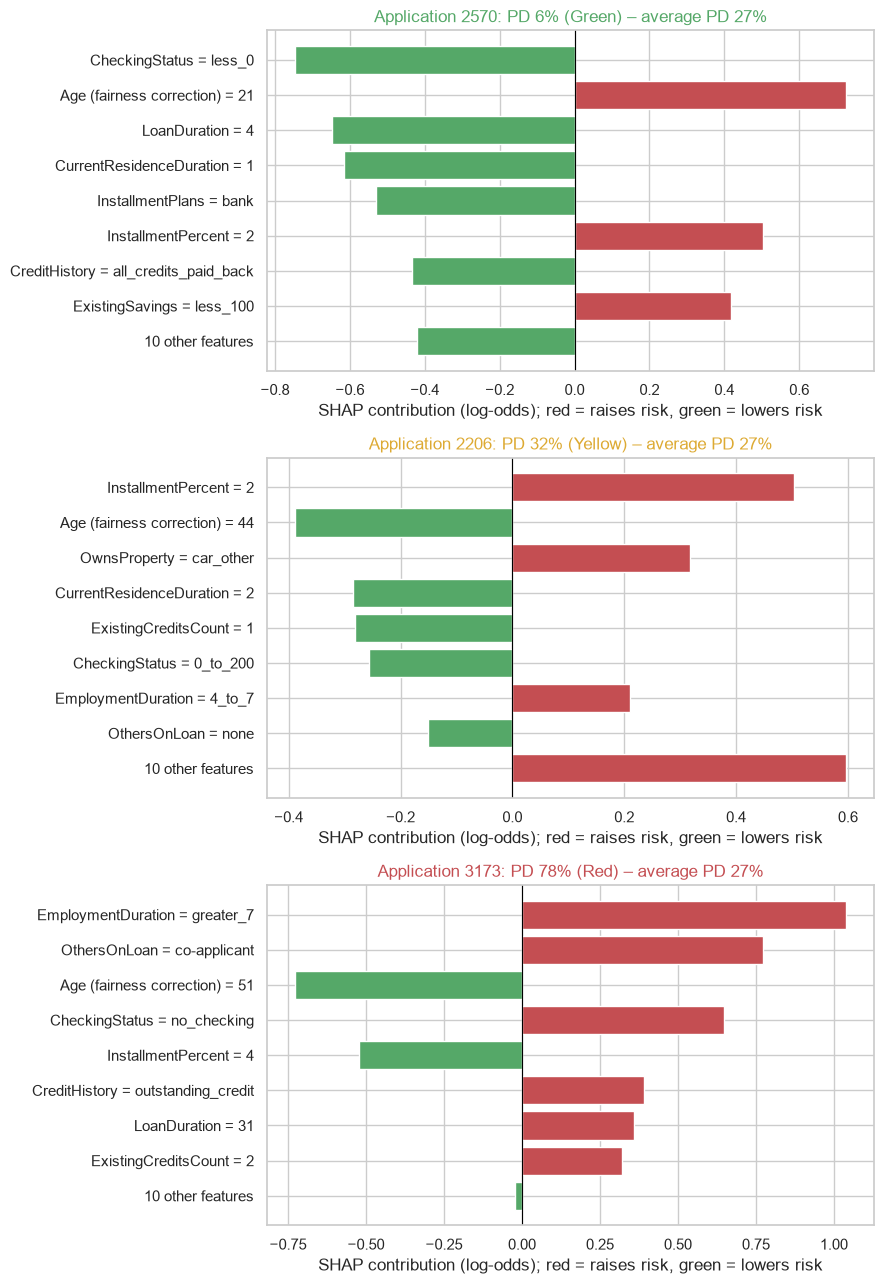

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(9, 13))
for ax, (z, idx) in zip(axes, examples.items()):
    plot_explanation(idx, ax=ax)
    ax.title.set_color(ZONE_COLORS[z])
plt.tight_layout()
plt.show()

**Plain-language reasons.** For the dashboard and the analyst's credit memo, we turn the largest contributions into short sentences.

In [12]:
def top_reasons(idx, model_name=FINAL, n=3, exclude=()):
    """The n largest risk-raising and risk-lowering factors as short sentences."""
    contrib = explainers[model_name](X_test.loc[[idx]])[0].iloc[0].drop(list(exclude))
    up = contrib[contrib > 0].sort_values(ascending=False).head(n)
    down = contrib[contrib < 0].sort_values().head(n)
    fmt = lambda f, v: f"{display_name(f) if model_name == FINAL else f} = {X_test.loc[idx, f]} ({v:+.2f})"
    return {"Raises risk": [fmt(f, v) for f, v in up.items()],
            "Lowers risk": [fmt(f, v) for f, v in down.items()]}

for z, idx in examples.items():
    r = top_reasons(idx)
    print(f"{z} zone – application {idx}, PD {pd_cp[idx]:.0%}")
    print("   Raises risk:", "; ".join(r["Raises risk"]))
    print("   Lowers risk:", "; ".join(r["Lowers risk"]))

Green zone – application 2570, PD 6%
   Raises risk: Age (fairness correction) = 21 (+0.73); InstallmentPercent = 2 (+0.50); ExistingSavings = less_100 (+0.42)
   Lowers risk: CheckingStatus = less_0 (-0.75); LoanDuration = 4 (-0.65); CurrentResidenceDuration = 1 (-0.62)
Yellow zone – application 2206, PD 32%
   Raises risk: InstallmentPercent = 2 (+0.50); OwnsProperty = car_other (+0.32); EmploymentDuration = 4_to_7 (+0.21)
   Lowers risk: Age (fairness correction) = 44 (-0.39); CurrentResidenceDuration = 2 (-0.28); ExistingCreditsCount = 1 (-0.28)
Red zone – application 3173, PD 78%
   Raises risk: EmploymentDuration = greater_7 (+1.04); OthersOnLoan = co-applicant (+0.77); CheckingStatus = no_checking (+0.65)
   Lowers risk: Age (fairness correction) = 51 (-0.73); InstallmentPercent = 4 (-0.52); ExistingSavings = 500_to_1000 (-0.22)


### c) Fair vs. comparison model for an older applicant

Step 6 showed that model (a) declines many creditworthy applicants aged 51+ automatically, while the CreditParity model sends most of them to an analyst. SHAP shows *why*: we take the good customer aged 51+ from the test set whose PD falls the most between model (a) and the CreditParity model, and compare the two explanations.

Application 4322: age 56, actually repaid
  Model (a): PD 82% -> zone Red (boundaries 0.11 / 0.58)
  CreditParity model: PD 53% -> zone Yellow (boundaries 0.13 / 0.62)


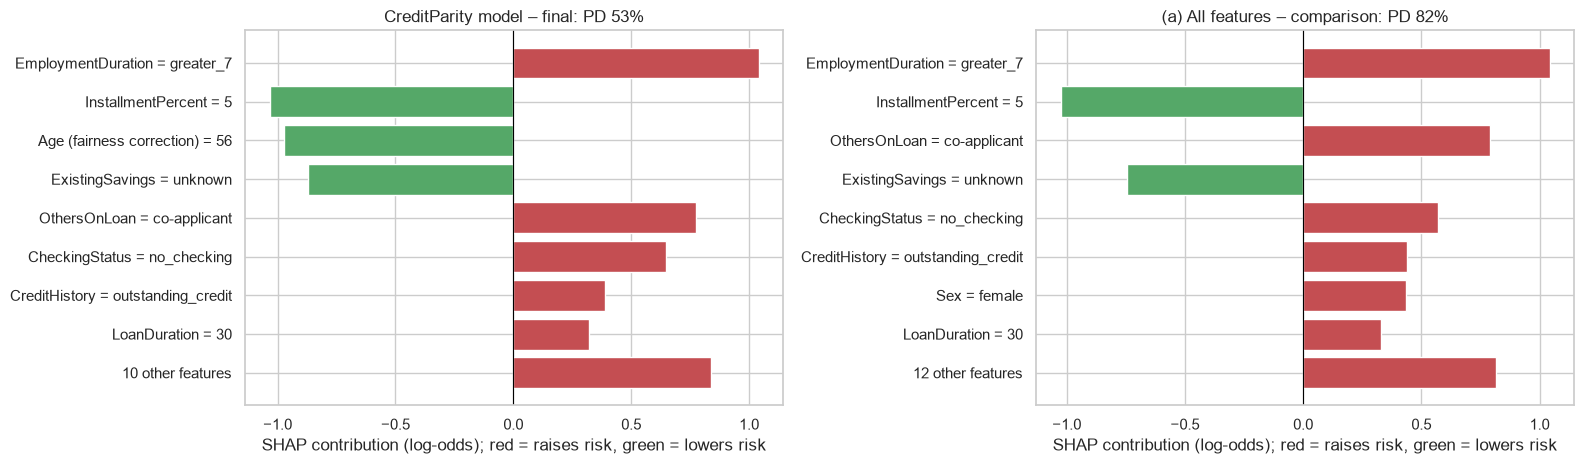

In [13]:
older_good = X_test.index[(X_test["Age"] > 50) & (y_test == 0)]
pd_a = pd.Series(p_test[COMPARISON], index=X_test.index)
case = (pd_a - pd_cp)[older_good].idxmax()
print(f"Application {case}: age {X_test.loc[case, 'Age']}, actually repaid")
print(f"  Model (a): PD {pd_a[case]:.0%} -> zone {zone_of(np.array([pd_a[case]]), 0.11, 0.58)[0]} (boundaries 0.11 / 0.58)")
print(f"  CreditParity model: PD {pd_cp[case]:.0%} -> zone {zone_of(np.array([pd_cp[case]]))[0]} (boundaries {T_LOWER} / {T_UPPER})")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, name in zip(axes, MODELS):
    plot_explanation(case, model_name=name, ax=ax,
                     title=f"{name}: PD {(pd_cp if name == FINAL else pd_a)[case]:.0%}")
plt.tight_layout()
plt.show()

### d) Sensitive features in the explanations

Model (a) uses age, gender and foreign worker status as inputs; the CreditParity model uses only age. How often is a sensitive feature among the top 3 drivers of an application?

In [14]:
rows = []
for name, s in shap_test.items():
    top3 = s.abs().apply(lambda r: list(r.sort_values(ascending=False).index[:3]), axis=1)
    rows.append({"Model": name,
                 **{f"{f} in top 3": top3.apply(lambda t: f in t).mean() for f in SENSITIVE},
                 "Any sensitive feature in top 3": top3.apply(lambda t: bool(set(t) & set(SENSITIVE))).mean()})
display(pd.DataFrame(rows).set_index("Model").round(3))

# For which applicants does Age raise the risk in the CreditParity model?
s_cp = shap_test[FINAL]
pd.DataFrame({"Age raises risk": (s_cp["Age"] > 0).groupby(age_group(X_test)).mean(),
              "Mean SHAP of Age": s_cp["Age"].groupby(age_group(X_test)).mean()}).round(3)

,Age in top 3,Sex in top 3,ForeignWorker in top 3,Any sensitive feature in top 3
Model,,,,
CreditParity model – final,0.327,0.000,0.0,0.327
(a) All features – comparison,0.000,0.136,0.0,0.136


,Age raises risk,Mean SHAP of Age
Age,,
19-25,1.0,0.729
26-35,1.0,0.259
36-50,0.0,-0.293
51+,0.0,-0.921


**Result (b–d) – explanations for individual applications.**
- **Typical cases** (test set, CreditParity model):
  - 🟢 *Green, PD 6%:* a negative checking balance (−0.75), a 4-month loan (−0.65) and a short residence duration (−0.62) lower the risk; **Age (fairness correction) = 21** is the largest factor raising it (+0.73), but the application is still approved automatically.
  - 🟡 *Yellow, PD 32%:* the installment rate (+0.50), the type of property (+0.32) and employment duration (+0.21) raise the risk; Age (fairness correction) = 44 (−0.39), residence duration and the number of existing loans lower it. A mixed picture, which is exactly what an analyst should look at.
  - 🔴 *Red, PD 78%:* employment over 7 years (+1.04), a co-applicant (+0.77) and no checking account (+0.65) drive the risk; Age (fairness correction) = 51 lowers it (−0.73).
- **Older applicant, CreditParity vs. comparison model.** A 56-year-old good customer gets a PD of 82% from model (a) (red zone, automatic decline) but 53% from the CreditParity model (yellow zone, an analyst decides). The explanation shows why: in the CreditParity model, **Age (fairness correction)** contributes −0.97 and offsets part of the risk that both models attribute to the age proxy "employment over 7 years" (+1.04 in both models).
- **Age appears in many explanations.** Age is among the top 3 drivers for **33%** of test applications in the CreditParity model; gender and foreign worker status never appear. In model (a), gender is among the top 3 for 14%. Age raises the risk of every applicant aged 35 or younger (mean contribution +0.73 for ages 19–25) and lowers it for everyone older (−0.92 for 51+).

**How CreditParity shows explanations.** In the MVP, explanations are **for the credit analyst only**. The analyst sees all drivers, and age is shown honestly as its own line, **"Age (fairness correction)"**, so it is clear that it partly offsets other features rather than penalizing or rewarding age as such. The plain-language reasons above are the basis for the analyst's view and credit memo in the dashboard (Step 9).

**Limitations.**
- **Customer-facing explanations are out of scope** for the MVP. Applicants who are declined automatically (red zone) have a right to meaningful information about the logic involved (GDPR Art. 22 and the related information duties). Designing that explanation, including how to communicate the age correction, is a next step that requires legal review.
- SHAP explains the **model**, not the causes of default. A feature with a large contribution is not necessarily a reason why someone defaults.
- Contributions are in log-odds and relative to the *average* applicant. They add up exactly, but they cannot be read directly as percentage points of the default probability.
- The linear SHAP values treat features as independent. When features are correlated (e.g. age and its proxies), the split of credit between them is a property of the model's coefficients, which is exactly what we see with `Age` and `EmploymentDuration`.
- Because the dataset is synthetic, some explanations are implausible (see part a).

### e) How large is the age correction?

To see the size of the age correction, we change **only** the age of one applicant and keep every other field fixed (a "what-if" analysis). We use the typical yellow-zone application from part (b) and the older good customer from part (c).

In [15]:
scaler = model_cp.named_steps["prep"].named_transformers_["num"]
age_pos = list(model_cp.named_steps["prep"].transformers_[1][2]).index("Age")
age_coef = pd.Series(model_cp.named_steps["model"].coef_[0],
                     index=model_cp.named_steps["prep"].get_feature_names_out())["num__Age"]
print(f"Age: mean {scaler.mean_[age_pos]:.1f}, standard deviation {scaler.scale_[age_pos]:.1f} years")
print(f"Coefficient: {age_coef:.3f} per standard deviation = {age_coef / scaler.scale_[age_pos]:.4f} log-odds per year")
print(f"Odds factor per 10 years younger: x{np.exp(-10 * age_coef / scaler.scale_[age_pos]):.2f}")

# SHAP breakdown of the yellow example at its own age and 10 years younger, all else equal
idx = examples["Yellow"]
pair = pd.concat([X_test.loc[[idx]], X_test.loc[[idx]].assign(Age=max(19, int(X_test.loc[idx, "Age"]) - 10))])
pair.index = [f"Age {a}" for a in pair["Age"]]
contrib, base = explainers[FINAL](pair)
changed_inputs = [c for c in pair.columns if pair.iloc[0][c] != pair.iloc[1][c]]
print("Inputs that differ between the two rows:", changed_inputs)
side = contrib.T.rename(index=display_name)
side["Difference"] = side.iloc[:, 1] - side.iloc[:, 0]
side = side.reindex(side[side.columns[0]].abs().sort_values(ascending=False).index)
total = pd.DataFrame({c: [base, base + contrib.loc[c].sum(), sigmoid(base + contrib.loc[c].sum())]
                      for c in contrib.index}, index=["Base value (average applicant)", "Log-odds", "Default probability"])
total["Difference"] = total.iloc[:, 1] - total.iloc[:, 0]
display(side.round(3))
total.round(3)

Age: mean 36.0, standard deviation 10.7 years
Coefficient: -0.518 per standard deviation = -0.0485 log-odds per year
Odds factor per 10 years younger: x1.62
Inputs that differ between the two rows: ['Age']


,Age 44,Age 34,Difference
InstallmentPercent,0.504,0.504,0.000
Age (fairness correction),-0.389,0.096,0.485
OwnsProperty,0.318,0.318,0.000
CurrentResidenceDuration,-0.284,-0.284,0.000
ExistingCreditsCount,-0.282,-0.282,0.000
CheckingStatus,-0.257,-0.257,0.000
EmploymentDuration,0.211,0.211,0.000
OthersOnLoan,-0.151,-0.151,0.000
Job,0.137,0.137,0.000
Telephone,0.126,0.126,0.000


,Age 44,Age 34,Difference
Base value (average applicant),-1.005,-1.005,0.000
Log-odds,-0.738,-0.253,0.485
Default probability,0.324,0.437,0.114


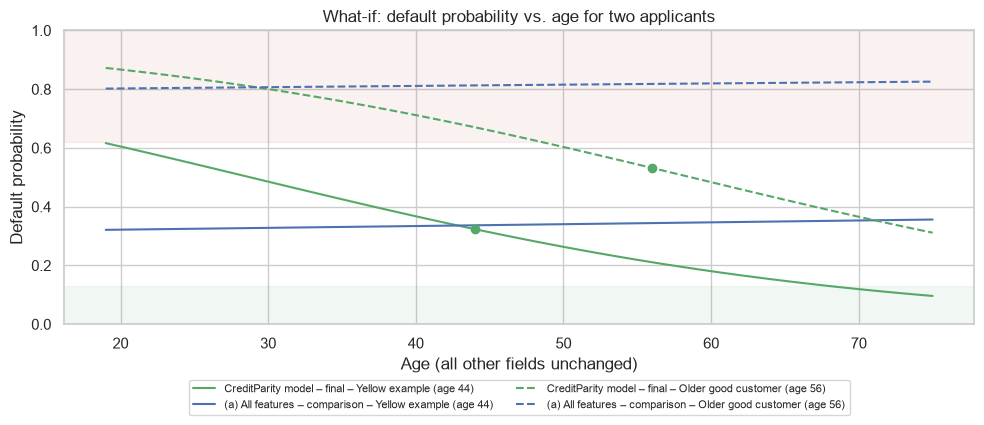

Yellow example (age 44), CreditParity model, zone by age: 19-67: Yellow | 68-75: Green
Older good customer (age 56), CreditParity model, zone by age: 19-48: Red | 49-75: Yellow


Applicant  Older good customer (age 56)                             \
Model     (a) All features – comparison CreditParity model – final   
Age                                                                  
19                                0.802                      0.872   
22                                0.803                      0.855   
25                                0.805                      0.836   
30                                0.807                      0.800   
35                                0.809                      0.759   
45                                0.813                      0.660   
55                                0.818                      0.544   
65                                0.822                      0.423   
75                                0.826                      0.311   

Applicant       Yellow example (age 44)                             
Model     (a) All features – comparison CreditParity model – final  
Age                                                                 
19                                0.321                      0.616  
22                                0.323                      0.582  
25                                0.325                      0.546  
30                                0.328                      0.485  
35                                0.331                      0.425  
45                                0.337                      0.313  
55                                0.344                      0.219  
65                                0.350                      0.147  
75                                0.356                      0.096

In [16]:
# Default probability vs. age, all else equal (ages 19-75)
ages = np.arange(19, 76)
cases = {f"Yellow example (age {X_test.loc[examples['Yellow'], 'Age']})": examples["Yellow"],
         f"Older good customer (age {X_test.loc[case, 'Age']})": case}
fig, ax = plt.subplots(figsize=(10, 4.5))
curve_rows = []
for (label, i), style in zip(cases.items(), ["-", "--"]):
    grid = pd.concat([X_test.loc[[i]]] * len(ages)).assign(Age=ages)
    for name, m in MODELS.items():
        p = m.predict_proba(grid)[:, 1]
        color = "#55A868" if name == FINAL else "#4C72B0"
        ax.plot(ages, p, style, color=color, label=f"{name} – {label}")
        curve_rows += [{"Applicant": label, "Model": name, "Age": a, "PD": v} for a, v in zip(ages, p)]
    ax.scatter([X_test.loc[i, "Age"]], [pd_cp[i]], color="#55A868", zorder=5)
ax.axhspan(0, T_LOWER, color=ZONE_COLORS["Green"], alpha=0.08)
ax.axhspan(T_UPPER, 1, color=ZONE_COLORS["Red"], alpha=0.08)
ax.set_xlabel("Age (all other fields unchanged)")
ax.set_ylabel("Default probability")
ax.set_ylim(0, 1)
ax.set_title("What-if: default probability vs. age for two applicants")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
plt.tight_layout()
plt.show()

curves = pd.DataFrame(curve_rows)
for label in cases:
    c = curves[(curves["Applicant"] == label) & (curves["Model"] == FINAL)]
    zone = pd.Series(zone_of(c["PD"].to_numpy()), index=c["Age"])
    spans = zone.groupby((zone != zone.shift()).cumsum()).apply(lambda z: f"{z.index.min()}-{z.index.max()}: {z.iloc[0]}")
    print(f"{label}, CreditParity model, zone by age: " + " | ".join(spans))
curves[curves["Age"].isin([19, 22, 25, 30, 35, 45, 55, 65, 75])].pivot_table(
    index="Age", columns=["Applicant", "Model"], values="PD").round(3)

In [17]:
# Real applicants: older age comes with different proxy values, so the effects partly cancel.
# Average predicted PD and age contribution by age group (test set)
by_age = pd.DataFrame({
    "Applications": age_group(X_test).value_counts().sort_index(),
    "Observed default rate": y_test.groupby(age_group(X_test)).mean(),
    "Mean PD model (a)": pd.Series(p_test[COMPARISON], index=X_test.index).groupby(age_group(X_test)).mean(),
    "Mean PD CreditParity model": pd_cp.groupby(age_group(X_test)).mean(),
    "Mean SHAP Age (CreditParity)": shap_test[FINAL]["Age"].groupby(age_group(X_test)).mean(),
    "Mean SHAP of all other features (CreditParity)": shap_test[FINAL].drop(columns="Age").sum(axis=1).groupby(age_group(X_test)).mean(),
})
by_age.round(3)

,Applications,Observed default rate,Mean PD model (a),Mean PD CreditParity model,Mean SHAP Age (CreditParity),Mean SHAP of all other features (CreditParity)
Age,,,,,,
19-25,195,0.051,0.069,0.138,0.729,-2.012
26-35,289,0.208,0.184,0.239,0.259,-0.820
36-50,428,0.460,0.469,0.430,-0.293,0.904
51+,88,0.761,0.753,0.631,-0.921,2.608


**Result (e) – how large the age correction is.**
- **Only age changes.** When the yellow example is made ten years younger (44 → 34), no other input or contribution moves; only the age contribution rises by 0.485 log-odds (= 10 years × 0.0485). The default probability rises from 32.4% to 43.7%.
- **Size.** The coefficient is −0.52 per standard deviation of age (10.7 years), i.e. **−0.049 log-odds per year**: ten years younger multiplies the odds of default by 1.62. Across ages 19–75, with everything else unchanged, the yellow applicant's default probability ranges from 62% to 10%, and the older good customer's from 87% to 31%. In model (a) the same curves are almost flat (32% → 36% and 80% → 83%).
- **Age can move an application across zones.** The yellow applicant stays in the yellow zone from 19 to 67 and would be green from 68; the older good customer would be red up to age 48 and is yellow from 49. At age 22, the yellow applicant's default probability would be 58%: still yellow, but close to the red boundary of 62%.
- **Why this direction?** In this dataset the default rate rises from 5% (ages 19–25) to 76% (51+) on the test set, and most of this age signal is carried by other features (Step 6: age 51+ can be predicted with ROC AUC 0.90). Partial reweighing weakens the link between age group and default in the training data, so the model offsets part of the age signal hidden in the proxies with an opposite age coefficient. Full reweighing would need a coefficient about twice as large (Step 6.4). For real applicants, age and proxies move together and partly cancel: on average, the other features add −2.01 log-odds for ages 19–25 and +2.61 for 51+, while age adds +0.73 and −0.92.
- **The what-if curve isolates the correction.** It keeps fields such as "employment over 7 years" fixed while age changes, which creates combinations that are rare in the data. It shows the size of the correction term, not the typical risk of a 20- or 70-year-old.
- **Consequence: the correction shifts predicted risk toward younger applicants.** The average predicted default probability is 13.8% for ages 19–25 (observed default rate 5.1%) and 63.1% for 51+ (observed 76.1%). This compression is how the CreditParity model reduces the age gap, but it means young applicants are rated riskier than their group's track record suggests: 30.5% of good customers aged 19–25 are not auto-approved (out-of-fold; 17% with model (a)), and for the same profile, a younger applicant always gets a higher default probability than an older one.